# Forecasting USDZAR one month ahead

Does a forecast combination beat the mandated AR(1) benchmark out of sample?

This notebook walks through the analysis: the data, the models, the out-of-sample
protocol, the results and the statistics. Everything below reads from the saved
outputs, so it runs in seconds and refits nothing. The pipeline that produced
them is `python src/run_all.py`.

| | |
|---|---|
| Forecasts | 261, one every Friday, 1 January 2021 to 26 December 2025 |
| Horizon | 28 days ahead |
| Combination | A weighted average of a random walk, a carry tilt and a shrunk ridge |
| Result | RMSE 0.5599 against 0.5624 for the AR(1), 0.44 per cent lower; 0.5600 for the random walk |
| Significance | Not established against the AR(1) (p = 0.449) or the random walk (p = 0.967); see section 6 |
| Status | All 2021 to 2025 results are exploratory |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

log = pd.read_csv(PROC / "forecast_log.csv", parse_dates=["origin", "target_date"])
metrics = json.load(open(PROC / "metrics.json"))
stats = json.load(open(PROC / "statistical_tests.json"))

print(f"{len(log)} forecasts, {log.origin.min().date()} to {log.origin.max().date()}")
log.head()

261 forecasts, 2021-01-01 to 2025-12-26


,origin,spot,target_date,realized,AR1_log,AR1_level,AR1_log_roll,AR1_log_vc,RW,RW_drift,CARRY,RIDGE,GBM,COMBO,EQUAL3,RW_CARRY,RW_RIDGE
0,2021-01-01,14.6246,2021-01-29,15.1903,14.598094,14.606781,14.566327,14.613654,14.6246,14.671840,14.664539,14.631240,14.713132,14.639931,14.640126,14.644235,14.627876
1,2021-01-08,15.3661,2021-02-05,14.9266,15.339439,15.351083,15.229773,15.355851,15.3661,15.418349,15.407946,15.369701,15.460627,15.381066,15.381249,15.386691,15.367877
2,2021-01-15,15.1810,2021-02-12,14.6610,15.154205,15.164922,15.072623,15.170406,15.1810,15.231932,15.222342,15.184310,15.272900,15.195737,15.195884,15.201388,15.182635
3,2021-01-22,15.0771,2021-02-19,14.5616,15.050330,15.060551,14.982248,15.066405,15.0771,15.127278,15.118275,15.081152,15.179042,15.092057,15.092176,15.097445,15.079102
4,2021-01-29,15.1903,2021-02-26,14.8367,15.163662,15.174357,15.086608,15.179847,15.1903,15.241207,15.231784,15.196196,15.240900,15.206006,15.206093,15.210846,15.193215


---
## 1. Why this problem is hard

Meese and Rogoff (1983) found that structural exchange-rate models lose to a
no-change forecast out of sample, even when handed the true future values of
their driving variables. Rossi's (2013) survey finds that forecasting success
depends on the sample, the predictor, the horizon and the benchmark.

A common explanation is that USDZAR is priced by a deep market, so public
information is in the price quickly and a month-ahead forecast is left with a
small residual. That is plausible, and nothing here tests it.

For the design it means differences between sensible forecasts will be small, and
a large improvement would be a reason to look for leakage first. Much of this
project went into making leakage hard to introduce, and into tests that fail if
it appears.

---
## 2. Data and the information set

The target is EXCX135, the SARB's rand-per-dollar rate, taken from the official
EconData export and checked independently against the SARB Web API: 9,141
overlapping observations, largest absolute difference 0.000000.

The predictors are daily market prices and rates.

| Predictor | Why |
|---|---|
| JIBAR 3M minus US 3M T-bill | the carry signal, from covered interest parity |
| Gold, platinum | South Africa exports both, so the commodity-currency channel applies |
| Brent | South Africa imports oil |
| Broad USD index | much of what looks like rand movement is dollar movement |
| VIX | global risk appetite, and the rand trades as a liquid EM proxy |

Macro series like CPI and the current account have a claim on a rand model, but
they are released late and revised afterwards, and the repository holds no
vintages for them, so they are left out.

The market series are not free of timing problems either. The forecast is issued
at 17:00 Johannesburg time on the Friday, and each series enters only once it was
public by then: Wednesday's T-bill rate, Thursday's VIX and platinum, the previous
Friday's dollar index, Brent up to the Monday. The dollar index, Brent, the T-bill
rate and the VIX are revised, so they carry the value the ALFRED vintage archive
showed at the time. `data/raw/series_metadata.json` holds each rule and its
source, and `weekly.csv` keeps the observation date and the publication time of
every input.

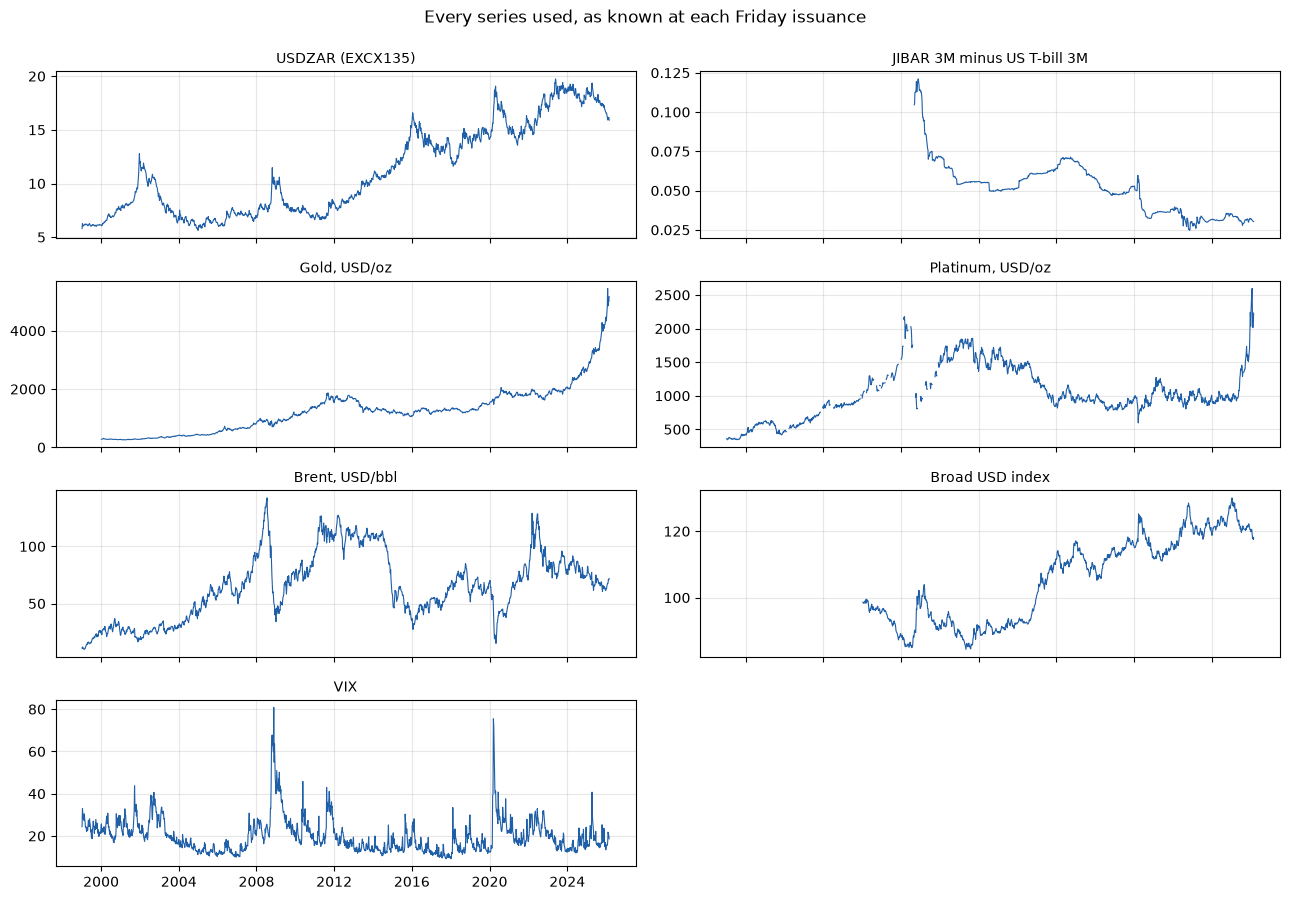

In [2]:
weekly = pd.read_csv(PROC / "weekly.csv", parse_dates=["friday"])
cols = ["spot", "carry_diff", "gold", "platinum", "brent", "usd_broad", "vix"]

fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
titles = ["USDZAR (EXCX135)", "JIBAR 3M minus US T-bill 3M", "Gold, USD/oz",
          "Platinum, USD/oz", "Brent, USD/bbl", "Broad USD index", "VIX"]
for ax, c, t in zip(axes.ravel(), cols, titles):
    ax.plot(weekly.friday, weekly[c], lw=0.8, color="#1F5FA8")
    ax.set_title(t, fontsize=10)
    ax.grid(alpha=0.3)
axes.ravel()[-1].axis("off")
fig.suptitle("Every series used, as known at each Friday issuance", y=0.995)
fig.tight_layout()

---
## 3. The out-of-sample protocol

At each Friday `t` a forecast may use only what was public by 17:00 Johannesburg
time that day, and forecasts the fixing 28 days later. Five rules make that
auditable.

1. Publication time. Every predictor joins on when its value became public, with
   the vintage then current for revised series.
2. Resolved-only training. A row of training data counts at origin `t` only once
   its target date is on or before `t`: `resolved(w, t)` filters on target dates.
3. Purged cross-validation. Ridge and boosting settings are chosen by time-ordered
   folds that drop training rows whose target date reaches into the validation
   fold, and the scaler is fitted inside each fold.
4. Embargoed weights. Combination weights use only errors from forecasts resolved
   by the current origin.
5. Selection before the judged window. The ridge variant, decay and sharpness were
   chosen on validation origins from 2 January 2015 to 27 November 2020, the last whose
   target (25 December 2020) falls before 2021. Those scores were used for
   selection, so they are not independent evidence. The full grid is in
   `data/processed/validation_metrics.json`.

The tests enforce these. One scrambles every raw input dated after a sampled
origin and requires each model's forecast at that origin to be unchanged. `pytest -q`
runs them.

In [3]:
val = json.load(open(PROC / "validation_metrics.json"))
print("Configuration selected on the validation era and then frozen:")
for k, v in val["chosen_config"].items():
    print(f"  {k:<10} {v}")
print(f"\nValidation era origins: {val['validation_era']['COMBO']['n']}")

Configuration selected on the validation era and then frozen:
  ridge      RIDGE_f0
  delta      0.97
  theta      2.0
  val_rmse   0.6592023309584955

Validation era origins: 309


---
## 4. The models

| Model | One line |
|---|---|
| AR(1) | The required benchmark. OLS with intercept on the weekly log level, expanding window from 1999, iterated four steps. |
| Random walk | Forecast equals today's rate. The strongest single benchmark at this horizon. |
| Carry | $\hat S_{t+28d} = S_t\left(1 + (i^{ZA}_t - i^{US}_t)\tfrac{28}{365}\right)$, the covered-interest-parity forward rate. |
| Ridge | 4-week log return on the predictor set chosen in validation (printed above). Scaler and ridge fitted together inside each purged CV fold, penalty re-chosen every 13 origins, no intercept, so heavy shrinkage collapses the model to the random walk. |
| Gradient boosting | Configuration picked every 52 weeks from 12 combinations by the same purged CV, included as a flexible comparator. |
| Combination | Inverse discounted-MSE weighted average of {RW, carry, ridge}, weights from resolved past errors only. |

Carry is the covered-interest-parity forward rate. It prices a forward contract and
is not an expected spot rate, and the three-month rates behind it do not match a
28-day horizon, so it is one component and not a claim about forecasting skill.

The no-intercept choice in the ridge matters. Under heavy shrinkage the predicted
return goes to zero, so the forecast becomes $S_t \cdot e^0 = S_t$ and a ridge that
finds no signal becomes the random walk.

---
## 5. What the AR(1) does differently

An AR(1) has persistence $\phi$. Ours estimates between 0.9971 and 0.9986,
just below one, so every forecast gets pulled towards a long-run level. For the log
series that level is

$$\mu = \exp\left(\frac{c}{1-\phi}\right)$$

which is fragile near a unit root, because $1-\phi$ is small. We recomputed $\mu$ at
all 261 origins and compared it with that day's spot rate.

In [4]:
# Refit the AR(1) at every origin and compare its implied mean with spot.
mus, phis = [], []
for t in log["origin"]:
    h = weekly[weekly.friday <= t]["spot"].dropna().values
    y = np.log(h)
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    c, phi = np.linalg.lstsq(X, y[1:], rcond=None)[0]
    mus.append(np.exp(c / (1 - phi)))
    phis.append(phi)

mus, phis = np.array(mus), np.array(phis)
gap = log["spot"].values - mus

print(f"phi ranges {phis.min():.4f} to {phis.max():.4f}")
print(f"implied mean ranges R{mus.min():.2f} to R{mus.max():.2f}")
print(f"below spot at {(mus < log['spot'].values).sum()} of {len(log)} origins")
print(f"average gap R{gap.mean():.2f}, smallest R{gap.min():.2f}")

phi ranges 0.9971 to 0.9986
implied mean ranges R11.80 to R19.18
below spot at 261 of 261 origins
average gap R2.11, smallest R0.57


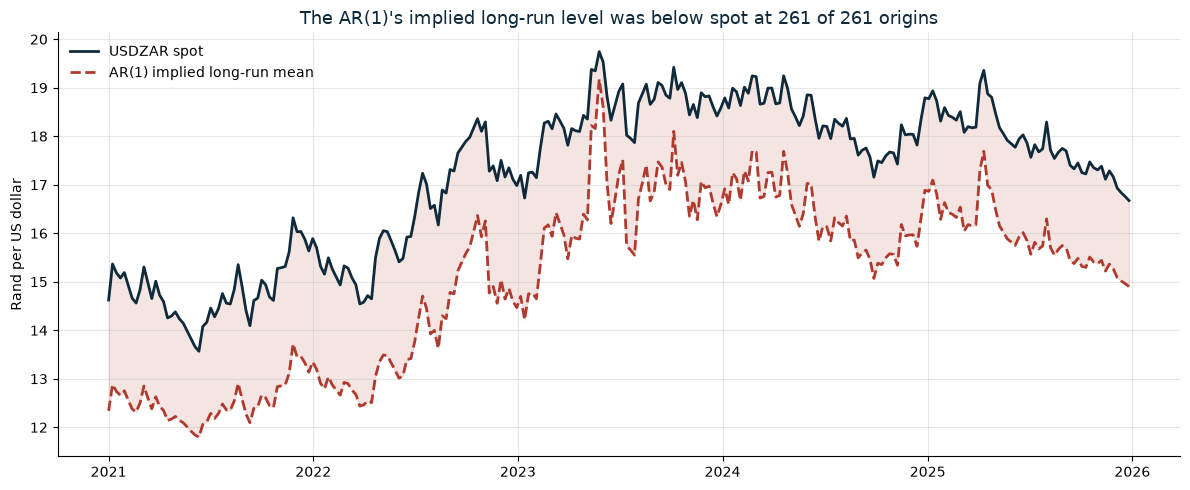

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(log.origin, log.spot, color="#0E2A3B", lw=2, label="USDZAR spot")
ax.plot(log.origin, mus, color="#B03A2E", lw=2, ls="--",
        label="AR(1) implied long-run mean")
ax.fill_between(log.origin, mus, log.spot, color="#B03A2E", alpha=0.13)
ax.set_title(f"The AR(1)'s implied long-run level was below spot at "
             f"{(mus < log['spot'].values).sum()} of {len(log)} origins",
             fontsize=13, color="#0E2A3B")
ax.set_ylabel("Rand per US dollar")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()

The shaded band is the gap between spot and the level the AR(1) is pulled towards. The
AR(1) never forecast a rise (0 per cent of origins), and its mean error
was -0.0393 against -0.0055 for the combination. Squared bias is
55 per cent of the AR(1)'s excess squared error against the
combination, and the rest is variance.

These are observations. I have not shown that the downward lean is the whole reason
the AR(1) scored worse, or that it would persist in another sample.

---
## 6. Results, and an honest reading of the statistics

In [6]:
rows = []
base = metrics["AR1_log"]["rmse"]
for m in ["AR1_log", "RW", "CARRY", "RIDGE", "GBM", "COMBO", "EQUAL3"]:
    rows.append({
        "model": m,
        "RMSE": round(metrics[m]["rmse"], 4),
        "MAE": round(metrics[m]["mae"], 4),
        "vs AR(1) %": round(100 * (1 - metrics[m]["rmse"] / base), 2),
        "DM p vs AR(1)": metrics[m].get("dm_vs_ar1", [None, None])[1],
    })
pd.DataFrame(rows).set_index("model")

,RMSE,MAE,vs AR(1) %,DM p vs AR(1)
model,,,,
AR1_log,0.5624,0.4478,0.00,NaN
RW,0.5600,0.4480,0.43,0.2181
CARRY,0.5606,0.4540,0.32,0.7601
RIDGE,0.5602,0.4479,0.38,0.2640
GBM,0.5745,0.4723,-2.16,0.3625
COMBO,0.5599,0.4495,0.44,0.4487
EQUAL3,0.5599,0.4495,0.44,NaN


4 of the 5 core models scored below the AR(1), but the
margins are small. The random walk scores 0.5600 and an equal-weight average of
the three components 0.5599, so the adaptive weighting adds nothing we can
measure. Gradient boosting scores 0.5745, the highest of the 13
models, and that holds for this specification only.

Two comparisons were fixed in advance: the combination against the AR(1) and
against the random walk. The rest are exploratory and carry Holm-adjusted p-values
(0 of 21 survive). The planning table asks how
many weekly origins a future holdout would need to detect RMSE cuts of 1, 2 and 5
per cent, under stated assumptions. Against the random walk the numbers are small
only because the two forecasts are nearly identical.

In [7]:
pre = [c for c in stats["comparisons"] if c["role"] == "prespecified"]
display(pd.DataFrame([{"comparison": f"{c['model']} vs {c['benchmark']}",
                       "RMSE diff": round(c["rmse_difference"], 5),
                       "DM (lag 3)": round(c["by_lag"]["3"]["dm"], 3),
                       "p": round(c["by_lag"]["3"]["p"], 3)} for c in pre]))
pd.DataFrame([dict(benchmark=b, **r) for b, t in stats["planning"]["vs"].items()
              for r in t["rows"]]).round(3)

,comparison,RMSE diff,DM (lag 3),p
0,COMBO vs RW,-0.00006,-0.042,0.967
1,COMBO vs AR1_log,-0.00245,-0.758,0.449


,benchmark,rmse_reduction_pct,mse_reduction,origins_needed,years_of_weekly_origins,power_at_current_n
0,RW,1,0.006,120,2.3,0.985
1,RW,2,0.012,31,0.6,1.000
2,RW,5,0.031,5,0.1,1.000
3,AR1_log,1,0.006,680,13.1,0.412
4,AR1_log,2,0.013,172,3.3,0.933
5,AR1_log,5,0.031,29,0.5,1.000


The combination is below the AR(1) in 4 of 5 years
(2021, 2022, 2023 and 2024) and above it in 2025. The cuts that look consistent
(the full window, the strict cut with targets inside 2025, the validation era) are
views of the same data or were used for selection, so they are not independent
confirmation. The rolling view below shows how thin the margin is.

ahead of the benchmark in 68% of rolling windows


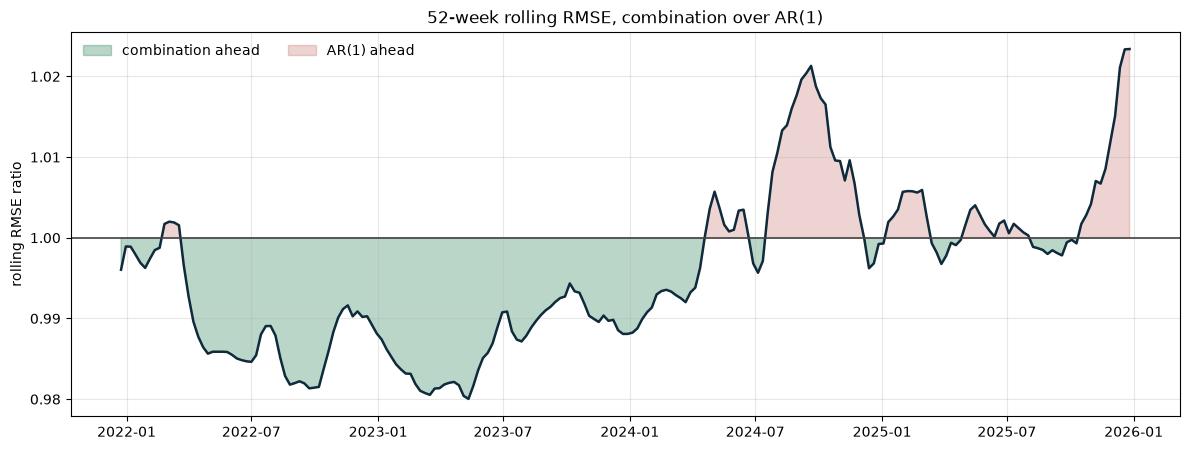

In [8]:
win = 52
roll = {m: np.sqrt(pd.Series((log[m] - log["realized"]).values ** 2,
                             index=log.origin).rolling(win).mean())
        for m in ["COMBO", "AR1_log"]}
ratio = (roll["COMBO"] / roll["AR1_log"]).dropna()

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.fill_between(ratio.index, 1, ratio.values, where=(ratio.values < 1),
                color="#1A7A4A", alpha=0.3, interpolate=True, label="combination ahead")
ax.fill_between(ratio.index, 1, ratio.values, where=(ratio.values >= 1),
                color="#B03A2E", alpha=0.22, interpolate=True, label="AR(1) ahead")
ax.plot(ratio.index, ratio.values, color="#0E2A3B", lw=1.8)
ax.axhline(1, color="#444444", lw=1.2)
ax.set_ylabel("rolling RMSE ratio")
ax.set_title("52-week rolling RMSE, combination over AR(1)", fontsize=12.5)
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()

print(f"ahead of the benchmark in {100 * (ratio < 1).mean():.0f}% of rolling windows")

---
## 7. One forecast, end to end

A single origin with every number on it. 3 June 2022, spot R15.4117, target
1 July 2022, actual R16.3482.

In [9]:
r = log[log.origin == "2022-06-03"].iloc[0]
w = pd.read_csv(PROC / "combo_weights.csv", index_col=0, parse_dates=True)
wr = w.loc[pd.Timestamp("2022-06-03")]

for m in ["RW", "CARRY", "AR1_log", "RIDGE", "GBM", "COMBO"]:
    print(f"{m:<9} forecast {r[m]:.4f}   error {r[m] - r['realized']:+.4f}")
print(f"\nweights: RW {wr.RW:.3f}, carry {wr.CARRY:.3f}, ridge {wr.RIDGE:.3f}")
print(f"check:   {wr.RW:.3f}*{r.RW:.4f} + {wr.CARRY:.3f}*{r.CARRY:.4f}"
      f" + {wr.RIDGE:.3f}*{r.RIDGE:.4f} = "
      f"{wr.RW * r.RW + wr.CARRY * r.CARRY + wr.RIDGE * r.RIDGE:.4f}")

RW        forecast 15.4117   error -0.9365
CARRY     forecast 15.4563   error -0.8919
AR1_log   forecast 15.3861   error -0.9621
RIDGE     forecast 15.4141   error -0.9341
GBM       forecast 15.5674   error -0.7808
COMBO     forecast 15.4275   error -0.9207

weights: RW 0.333, carry 0.337, ridge 0.331
check:   0.333*15.4117 + 0.337*15.4563 + 0.331*15.4141 = 15.4275


Every model forecast too low. The AR(1) has the largest error of the six. Its fit that day had
phi = 0.997531 and a long-run level of R13.01, against spot of
R15.41.

The forecasts range from 15.386 to 15.567, a spread of
18 cents, against an actual move of 94 cents. At a
one-month horizon the models stay close to the current price.

---
## 8. What the results support, and what they do not

What they support: an out-of-sample design with checks that can fail, over
261 origins, and a combination whose RMSE (0.5599) is
0.44 per cent below the AR(1)'s (0.5624) and level with the
random walk's (0.5600).

What they do not: a statistically established improvement over either benchmark,
any advantage for adaptive weighting over equal weights, directional information
(the combination forecast a rise at 100 per cent of origins and its
directional accuracy of 46.4 per cent equals the share of rises),
profitability, which was never tested, or persistence outside this sample.

All 2021 to 2025 results are exploratory: the window was scored repeatedly while the
code was built and repaired, and comparisons were added after earlier results had
been seen. `docs/METHODOLOGY.md` sets out a prospective-holdout protocol.

Where I would go next.

1. Option-implied volatility and risk reversals. Greenwood-Nimmo, Steenkamp and van
   Jaarsveld (SARB WP/22/14) report that distributional information about rand
   returns improves forecasts.
2. Density rather than point forecasts, which matter more for hedging decisions.
3. Bayesian model averaging over a wider component set.
4. Horizon sensitivity: repeat at 1, 2, 8 and 12 weeks.

---

*Built for the SES x Codera Analytics Hackathon, July 2026. Full write-up in
[`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md), technical report in
[`reports/technical_report.pdf`](../reports/technical_report.pdf).*